<a href="https://colab.research.google.com/github/Raj-18-45/-javascript-projects/blob/main/Supervised%20Learning/Decision_Tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 **Diabetes Prediction Using Decision Tree Classification**

Objective

To build a Decision Tree classification model to predict whether a person has diabetes based on medical attributes.

About the Dataset

The Pima Indians Diabetes dataset (diabetes.csv) contains 768 records and 9 columns. It includes medical information such as pregnancies, glucose level, blood pressure, skin thickness, insulin, BMI, diabetes pedigree function, and age.

The Outcome column is the target variable:

* 0: No diabetes
* 1: Diabetes present

In [20]:
#Import Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix

In [5]:
#Load and Explore the Dataset
df=pd.read_csv('/diabetes.csv')
print(df.head())
print(df.describe())
print(df.info())
print(df.shape)

   Pregnancies  Glucose  BloodPressure  ...  DiabetesPedigreeFunction  Age  Outcome
0            6      148             72  ...                     0.627   50        1
1            1       85             66  ...                     0.351   31        0
2            8      183             64  ...                     0.672   32        1
3            1       89             66  ...                     0.167   21        0
4            0      137             40  ...                     2.288   33        1

[5 rows x 9 columns]
       Pregnancies     Glucose  ...         Age     Outcome
count   768.000000  768.000000  ...  768.000000  768.000000
mean      3.845052  120.894531  ...   33.240885    0.348958
std       3.369578   31.972618  ...   11.760232    0.476951
min       0.000000    0.000000  ...   21.000000    0.000000
25%       1.000000   99.000000  ...   24.000000    0.000000
50%       3.000000  117.000000  ...   29.000000    0.000000
75%       6.000000  140.250000  ...   41.000000    1.0

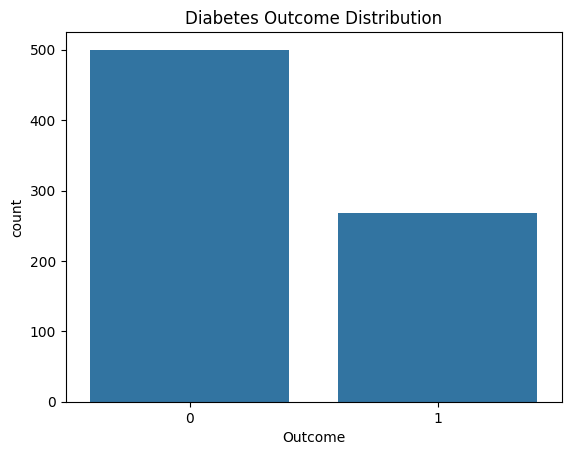

In [9]:
#Data visulization
sns.countplot(data=df,x='Outcome')
plt.title("Diabetes Outcome Distribution")
plt.show()

In [6]:
#Handle Missing Values
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols]=df[cols].replace(0,np.nan)
df[cols]=df[cols].fillna(df[cols].median())

In [10]:
#Separate Input and Output Variables
X=df.drop('Outcome',axis=1)
y=df['Outcome']

In [12]:
#Split the Dataset
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [13]:
#Train the Decision Tree Model
model= DecisionTreeClassifier(max_depth=4,random_state=42)
model.fit(X_train,y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [14]:
#Make Predictions
y_pred=model.predict(X_test)
print("predicted_values:",y_pred)

predicted_values: [1 0 0 0 0 1 0 1 1 1 1 1 1 1 0 0 0 0 1 0 1 0 1 0 1 1 0 0 0 0 1 1 1 1 1 1 1
 1 1 1 0 0 1 1 0 1 1 0 0 1 0 1 1 0 0 0 0 0 0 1 1 0 0 0 0 0 0 1 0 1 1 0 0 0
 0 1 0 0 0 1 1 0 0 1 0 1 1 1 1 0 0 0 0 1 0 1 1 0 1 0 1 0 1 1 1 0 0 1 0 1 0
 1 0 1 0 0 0 1 0 1 0 0 1 0 1 1 1 1 1 1 1 1 0 0 1 1 0 1 1 0 0 0 0 0 0 0 0 0
 1 1 0 1 0 0]


In [15]:
#Evaluate the Model
print("Accuracy:",accuracy_score(y_test,y_pred))
cm=confusion_matrix(y_test,y_pred)
print("Confusion Matrix:",cm)



Accuracy: 0.7077922077922078
Confusion Matrix: [[67 32]
 [13 42]]


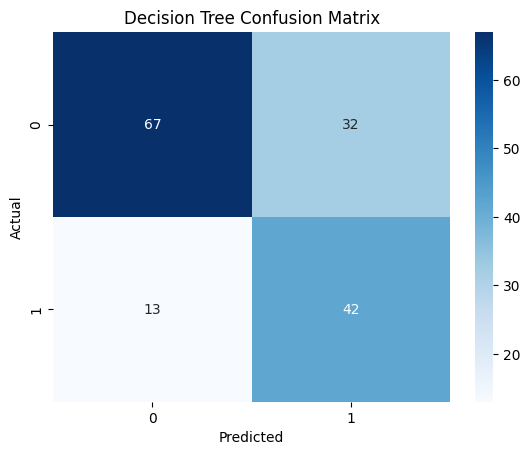

In [16]:
#Visualize the Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Decision Tree Confusion Matrix")

plt.show()

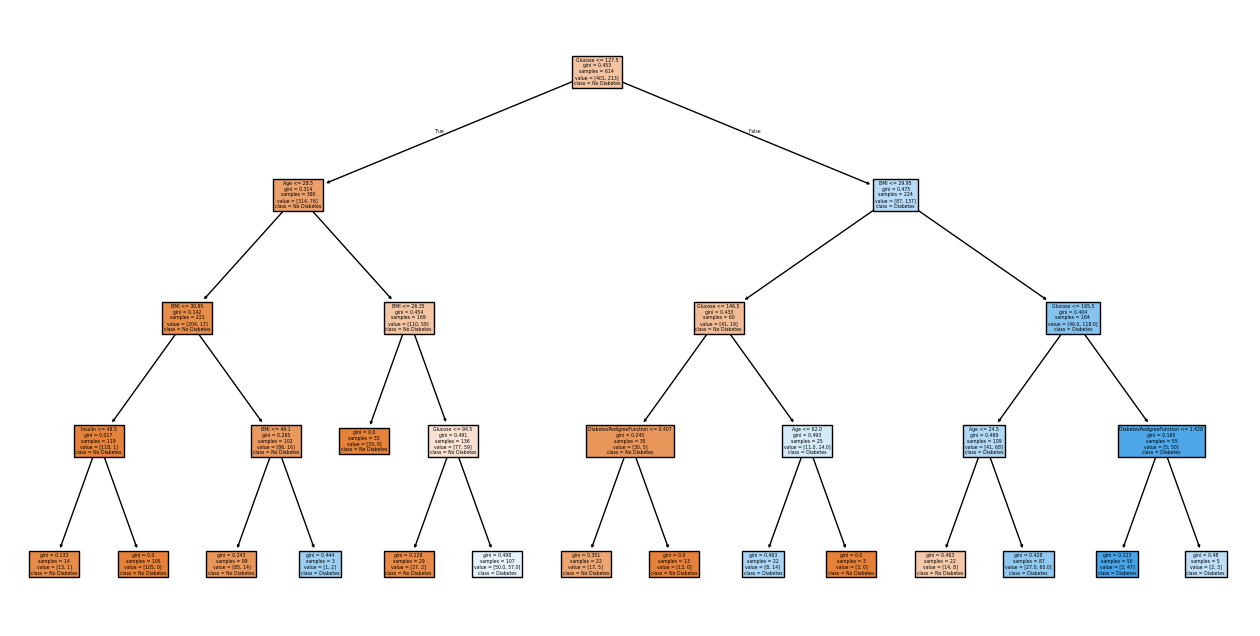

In [21]:
#Visualize the Decision Tree
plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=['No Diabetes', 'Diabetes'],
    filled=True
)

plt.show()